# FIFA World Cup 2026 – Linear Regression 2.1: predicting goal difference

**Task:** predict the goal difference (team A − team B), of each of the 104 World Cup 2026 matches from 8 pre-match explanatory variables.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
DIVERGING = mcolors.LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED = 42

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Helper functions
Reusable functions for descriptive statistics, plots and cross-validation.

In [2]:
# descriptive statistics ( mean, median, SD, IQR, CV, 1.5×IQR rule)
def describe(df, cols):
    out = []
    for c in cols:
        x = df[c]
        q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        n_out = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum() if (x.nunique() > 3 and iqr > 0) else 0
        out.append({"variable": c, "mean": x.mean(), "median": x.median(), "sd": x.std(),
                    "min": x.min(), "max": x.max(), "IQR": iqr,
                    "CV": x.std() / abs(x.mean()) if x.mean() != 0 else np.nan,
                    "outliers_1.5IQR": n_out})
    return pd.DataFrame(out).set_index("variable")

def mean_ci(x, z=1.960):
    """95% confidence interval for a mean using z* (n >= 30, CLT)."""
    m, se = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    return m, m - z * se, m + z * se

def hist_grid(df, cols, name, title):
    fig, axes = plt.subplots(2, 4, figsize=(12, 5))
    for ax, c in zip(axes.flat, cols):
        ax.hist(df[c], bins=15, color=BLUE, edgecolor="white", linewidth=1)
        ax.axvline(df[c].mean(), color=ORANGE, lw=2, label="mean")
        ax.set_title(c, fontsize=9); ax.set_ylabel("count")
    axes.flat[0].legend(frameon=False, fontsize=8)
    fig.suptitle(title, fontweight="bold"); fig.tight_layout(); save(fig, name); plt.show()

def target_correlations(df, cols, y):
    rows = []
    for c in cols:
        r, p = stats.pearsonr(df[c], df[y])
        rows.append({"variable": c, "r": r, "p_value": p, "significant": p <= 0.05})
    return pd.DataFrame(rows).set_index("variable").sort_values("r", key=abs, ascending=False)

def plot_target_corr(tc, name, title):
    fig, ax = plt.subplots(figsize=(6, 3.4))
    tc = tc.sort_values("r", key=abs)
    colors = [BLUE if s else GREY for s in tc["significant"]]
    ax.barh(tc.index, tc["r"], color=colors, height=0.6)
    ax.axvline(0, color=INK2, lw=1)
    for i, (r, s) in enumerate(zip(tc["r"], tc["significant"])):
        ax.text(r + (0.02 if r >= 0 else -0.02), i, f"{r:.2f}", va="center",
                ha="left" if r >= 0 else "right", fontsize=8, color=INK if s else INK2)
    ax.set_xlabel("Pearson r with target"); ax.set_title(title)
    ax.set_xlim(min(-0.1, tc.r.min() - 0.15), max(0.1, tc.r.max() + 0.15))
    ax.text(1, -0.3, "blue = significant at p ≤ 0.05, grey = not significant", transform=ax.transAxes,
            ha="right", fontsize=7.5, color=INK2)
    fig.tight_layout(); save(fig, name); plt.show()

def plot_corr_heatmap(df, cols, name, title):
    corr = df[cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    fig, ax = plt.subplots(figsize=(6.4, 5.2))
    sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f",
                annot_kws={"size": 7.5}, linewidths=2, linecolor="white", square=True,
                cbar_kws={"shrink": .7, "label": "Pearson r"}, ax=ax)
    ax.set_title(title); ax.grid(False)
    fig.tight_layout(); save(fig, name); plt.show()

def vif(df, cols):
    X = sm.add_constant(df[cols])
    return pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(cols))],
                     index=cols, name="VIF").sort_values(ascending=False)

def eda_subset(tc, df, cols, r_limit=0.8):
    """EDA-informed subset: keep variables significantly correlated with the target,
    then drop the weaker of any pair whose mutual |r| exceeds r_limit (redundant information)."""
    keep = [c for c in tc.index if tc.loc[c, "significant"]]
    corr = df[cols].corr().abs()
    for a in list(keep):
        for b in list(keep):
            if a != b and a in keep and b in keep and corr.loc[a, b] > r_limit:
                keep.remove(b if abs(tc.loc[a, "r"]) >= abs(tc.loc[b, "r"]) else a)
    return keep

In [3]:
from sklearn.preprocessing import FunctionTransformer

class ColumnSelector(BaseEstimator, TransformerMixin):
    """Keep only some columns (used for the EDA-informed subset)."""
    def __init__(self, cols): self.cols = cols
    def fit(self, X, y=None): return self
    def transform(self, X): return X[self.cols]

class IQRClipper(BaseEstimator, TransformerMixin):
    """Pull extreme values back to the 1.5×IQR fences (winsorising).
    Fences are learnt on the TRAINING fold only, so there is no leakage.
    Binary/3-level variables, and variables whose IQR is 0 (mostly one value), are left untouched."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(.25), X.quantile(.75); iqr = q3 - q1
        small = (X.nunique() <= 3) | (iqr == 0)
        self.lo_ = (q1 - 1.5 * iqr).where(~small, -np.inf)
        self.hi_ = (q3 + 1.5 * iqr).where(~small, np.inf)
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(self.lo_, self.hi_, axis=1)

def cap_rest(X):
    """Cap the single rest_diff data error (Saudi Arabia vs Uruguay, -70) at the most extreme genuine values."""
    X = X.copy(); X["rest_diff"] = X["rest_diff"].clip(-8, 6); return X

def build_models(subset=None):
    return {
        "Baseline (predict mean)": DummyRegressor(strategy="mean"),
        "Linear regression (OLS)": make_pipeline(FunctionTransformer(cap_rest), LinearRegression()),
    }

def cross_validate(models, X, y, groups=None, k=5, repeats=10):
    """Repeated (grouped) k-fold CV. All models share each split, so fold errors are paired."""
    scores, oof = [], {m: np.zeros(len(y)) for m in models}
    for rep in range(repeats):
        if groups is None:
            splits = KFold(k, shuffle=True, random_state=SEED + rep).split(X)
        else:
            splits = GroupKFold(k, shuffle=True, random_state=SEED + rep).split(X, y, groups)
        for fold, (tr, te) in enumerate(splits):
            for name, model in models.items():
                m = clone(model).fit(X.iloc[tr], y.iloc[tr])
                pred = m.predict(X.iloc[te])
                if rep == 0:
                    oof[name][te] = pred
                scores.append({"model": name, "repeat": rep, "fold": fold,
                               "RMSE": np.sqrt(mean_squared_error(y.iloc[te], pred)),
                               "MAE": mean_absolute_error(y.iloc[te], pred),
                               "R2": r2_score(y.iloc[te], pred)})
    return pd.DataFrame(scores), oof

def summarise(scores):
    base = scores[scores.model == "Baseline (predict mean)"].set_index(["repeat", "fold"])["RMSE"]
    rows = []
    for name, g in scores.groupby("model", sort=False):
        diff = g.set_index(["repeat", "fold"])["RMSE"] - base     # paired differences vs baseline
        t, p = stats.ttest_1samp(diff, 0) if diff.abs().sum() > 0 else (np.nan, np.nan)
        rows.append({"model": name, "RMSE": g.RMSE.mean(), "RMSE_sd": g.RMSE.std(),
                     "MAE": g.MAE.mean(), "R2": g.R2.mean(),
                     "RMSE_gain_vs_baseline_%": -100 * diff.mean() / base.mean(),
                     "t_vs_baseline": t, "p_vs_baseline": p})
    return pd.DataFrame(rows).set_index("model").sort_values("RMSE")

def plot_comparison(summary, name, title):
    s = summary.sort_values("RMSE", ascending=False)
    best = s["RMSE"].idxmin()
    fig, ax = plt.subplots(figsize=(7, 3.6))
    y = np.arange(len(s))
    colors = [ORANGE if m == best else GREY if m.startswith("Baseline") else BLUE for m in s.index]
    ax.errorbar(s["RMSE"], y, xerr=s["RMSE_sd"], fmt="none", ecolor="#c9c8c3", elinewidth=2, capsize=0)
    ax.scatter(s["RMSE"], y, s=70, color=colors, zorder=3, edgecolor="white", linewidth=2)
    for yi, v, sd in zip(y, s["RMSE"], s["RMSE_sd"]):
        ax.text(v + sd + 0.02, yi, f"{v:.3f}", va="center", ha="left", fontsize=7.5, color=INK2)
    ax.set_xlim(right=(s["RMSE"] + s["RMSE_sd"]).max() * 1.08)
    ax.axvline(s.loc[[m for m in s.index if m.startswith("Baseline")][0], "RMSE"],
               color=GREY, ls="--", lw=1)
    ax.set_yticks(y, s.index); ax.set_xlabel("Cross-validated RMSE (mean ± 1 SD over 50 folds) – lower is better")
    ax.set_title(title); ax.grid(axis="y", visible=False)
    fig.tight_layout(); save(fig, name); plt.show()

def coef_table(df, cols, y):
    """Full-data OLS fit for interpretation: coefficients, 95% CIs, p-values, standardised betas."""
    X = sm.add_constant(df[cols]); fit = sm.OLS(df[y], X).fit()
    ci = fit.conf_int()
    t = pd.DataFrame({"coef": fit.params, "CI_low": ci[0], "CI_high": ci[1], "p_value": fit.pvalues})
    sd = df[cols].std(); t.loc[cols, "std_beta"] = fit.params[cols] * sd / df[y].std()
    return fit, t

def plot_std_betas(t, name, title):
    s = t.dropna(subset=["std_beta"]).sort_values("std_beta", key=abs)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    colors = [BLUE if p <= 0.05 else GREY for p in s.p_value]
    ax.barh(s.index, s.std_beta, color=colors, height=0.6); ax.axvline(0, color=INK2, lw=1)
    ax.set_xlabel("Standardised coefficient (SD change in target per 1 SD of variable)")
    ax.set_title(title)
    ax.text(1, -0.3, "blue = p ≤ 0.05", transform=ax.transAxes, ha="right", fontsize=7.5, color=INK2)
    fig.tight_layout(); save(fig, name); plt.show()

def plot_diagnostics(y, pred, name, title, target_label):
    res = y - pred
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(y))
    ax = axes[0]
    ax.scatter(pred, y + jitter, s=18, color=BLUE, alpha=.7, edgecolor="white", linewidth=.5)
    xl = [pred.min() - .3, pred.max() + .3]
    ax.plot(xl, xl, color=ORANGE, lw=2, label="perfect prediction"); ax.set_xlim(xl)
    ax.legend(frameon=False, fontsize=7.5, loc="upper left")
    ax.set_xlabel(f"Predicted {target_label}"); ax.set_ylabel(f"Actual {target_label} (jittered)")
    ax.set_title("Predicted vs actual (out-of-fold)")
    ax = axes[1]
    ax.scatter(pred, res, s=18, color=BLUE, alpha=.7, edgecolor="white", linewidth=.5)
    ax.axhline(0, color=ORANGE, lw=2); ax.set_xlabel("Predicted"); ax.set_ylabel("Residual")
    ax.set_title("Residuals vs predicted")
    ax = axes[2]
    ax.hist(res, bins=15, color=BLUE, edgecolor="white"); ax.axvline(0, color=ORANGE, lw=2)
    ax.set_xlabel("Residual"); ax.set_ylabel("count"); ax.set_title("Residual distribution")
    fig.suptitle(title, fontweight="bold"); fig.tight_layout(); save(fig, name); plt.show()

In [4]:
import os, shutil
DATA_FILE = "data/dataset_2_1_goal_difference.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        up = files.upload()
        for name in up:
            shutil.move(name, DATA_FILE)
    except ImportError:
        raise FileNotFoundError(f"Put dataset_2_1_goal_difference.csv in a folder called 'data' next to this notebook")
print("Dataset found:", os.path.exists(DATA_FILE))

Saving dataset_2_1_goal_difference.csv to dataset_2_1_goal_difference.csv
Dataset found: True


---
## 2. Linear Regression 2.1 – Goal difference per match
Target: `goal_diff` = team A goals − team B goals (team A = the team listed first in FIFA's fixture). Each of the 8 explanatory variables is a pre-match comparison of team A with team B.

| Variable | Meaning (team A − team B) |
|---|---|
| `rank_diff` | FIFA rank of B − FIFA rank of A (positive = A ranked higher) |
| `elo_diff` | pre-match Elo rating of A − Elo of B |
| `host_diff` | host flag A − host flag B (−1, 0, 1) |
| `rest_diff` | rest days since the previous match, A − B |
| `wc_apps_diff` | previous World Cup appearances, A − B (experience) |
| `form_ppg_diff` | points per game over the last 10 internationals before the tournament, A − B |
| `h2h_gd_pg` | A's average goal difference per game in previous meetings with B (0 if never met) |
| `elo_momentum_diff` | change in Elo over the previous 12 months, A − B |

In [5]:
d21 = pd.read_csv("data/dataset_2_1_goal_difference.csv")
# use the same column names as the rest of the notebook
d21 = d21.rename(columns={"match_id": "match_no", "team_a": "team1", "team_b": "team2"})
Y21 = "goal_diff"
X21 = ["rank_diff", "elo_diff", "host_diff", "rest_diff",
       "wc_apps_diff", "form_ppg_diff", "h2h_gd_pg", "elo_momentum_diff"]
d21[X21] = d21[X21].round(3)          # tidy floating-point noise, e.g. 317.20000000000005 -> 317.2
assert d21.shape[0] == 104 and len(X21) == 8 and d21[X21 + [Y21]].notna().all().all()
print(d21.shape); d21.head()

(104, 13)


,match_no,team1,team2,stage,rank_diff,elo_diff,host_diff,rest_diff,wc_apps_diff,form_ppg_diff,h2h_gd_pg,elo_momentum_diff,goal_diff
0,1,Mexico,South Africa,Group,46,317.2,1,2,14,0.4,1.250,75.5,2
1,2,South Korea,Czech Republic,Group,14,77.3,0,1,2,0.0,-1.333,15.7,1
2,3,Canada,Bosnia and Herzegovina,Group,34,247.0,1,1,1,0.2,0.000,-74.0,0
3,4,United States,Paraguay,Group,23,-92.1,1,-1,3,0.2,0.556,-0.8,3
4,5,Qatar,Switzerland,Group,-38,-390.0,0,0,-11,-1.2,1.000,-160.0,0


### Explatory Data Analysis

Mean goal difference = 0.50  (95% CI 0.11 to 0.89),  median = 0.0,  SD = 2.02
Draws: 24 of 104
One-sample t-test vs 0: t(103) = 2.53, p = 0.013


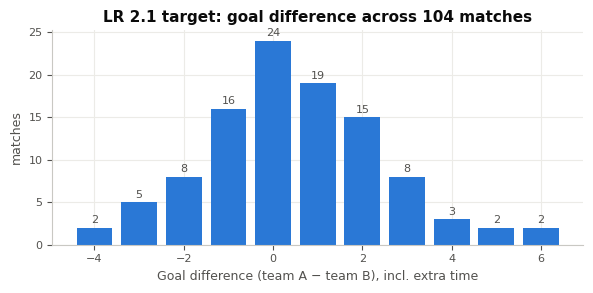

In [6]:
m, lo, hi = mean_ci(d21[Y21])
print(f"Mean goal difference = {m:.2f}  (95% CI {lo:.2f} to {hi:.2f}),  median = {d21[Y21].median()},  SD = {d21[Y21].std():.2f}")
print("Draws:", (d21[Y21] == 0).sum(), "of", len(d21))

# One-sample t-test
t, p = stats.ttest_1samp(d21[Y21], 0)
print(f"One-sample t-test vs 0: t({len(d21)-1}) = {t:.2f}, p = {p:.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
vals = d21[Y21].value_counts().sort_index()
ax.bar(vals.index, vals.values, color=BLUE, width=0.8)
for x, v in vals.items(): ax.text(x, v + 0.5, v, ha="center", fontsize=8, color=INK2)
ax.set_xlabel("Goal difference (team A − team B), incl. extra time"); ax.set_ylabel("matches")
ax.set_title("LR 2.1 target: goal difference across 104 matches")
fig.tight_layout(); save(fig, "21_target_distribution"); plt.show()

### Explanatory Variables

In [7]:
describe(d21, X21)

,mean,median,sd,min,max,IQR,CV,outliers_1.5IQR
variable,,,,,,,,
rank_diff,7.558,6.50,33.514,-76.0,77.000,41.500,4.434,1
elo_diff,57.104,51.30,222.102,-496.5,565.600,317.600,3.889,0
host_diff,0.125,0.00,0.360,-1.0,1.000,0.000,2.883,0
rest_diff,-0.490,0.00,7.015,-70.0,6.000,1.000,14.304,9
wc_apps_diff,2.875,2.00,8.640,-18.0,21.000,11.500,3.005,0
form_ppg_diff,0.070,0.05,0.682,-2.0,1.600,0.900,9.711,1
h2h_gd_pg,-0.023,0.00,1.355,-5.0,5.333,1.178,57.810,7
elo_momentum_diff,-12.712,-22.20,73.532,-168.7,158.400,109.800,5.785,0


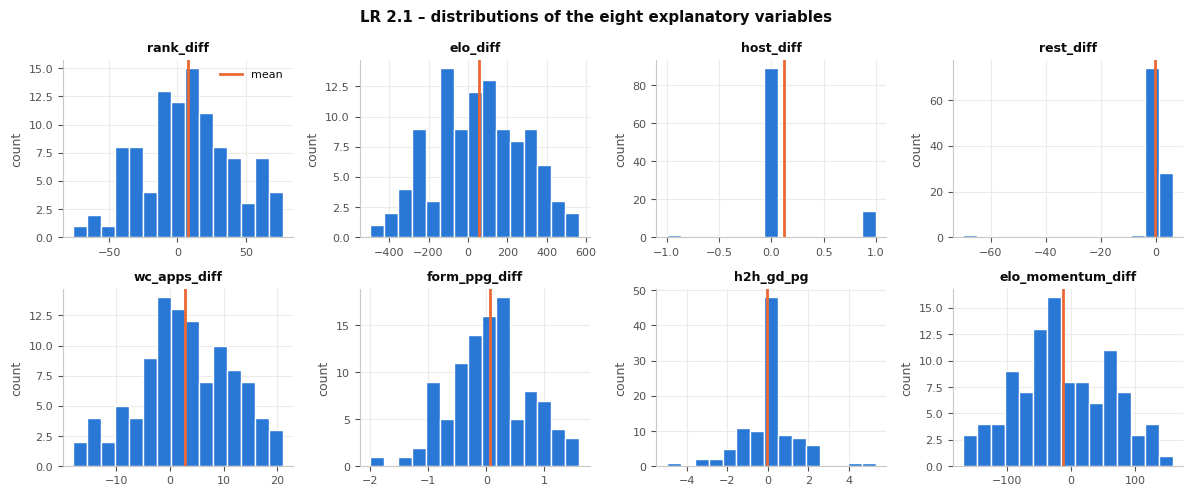

In [8]:
hist_grid(d21, X21, "21_feature_histograms", "LR 2.1 – distributions of the eight explanatory variables")

,r,p_value,significant
variable,,,
rank_diff,0.621,1.927e-12,True
elo_diff,0.614,3.993e-12,True
form_ppg_diff,0.565,4.044e-10,True
wc_apps_diff,0.530,7.206e-09,True
h2h_gd_pg,0.358,1.927e-04,True
host_diff,0.087,3.814e-01,False
elo_momentum_diff,0.085,3.935e-01,False
rest_diff,0.043,6.659e-01,False


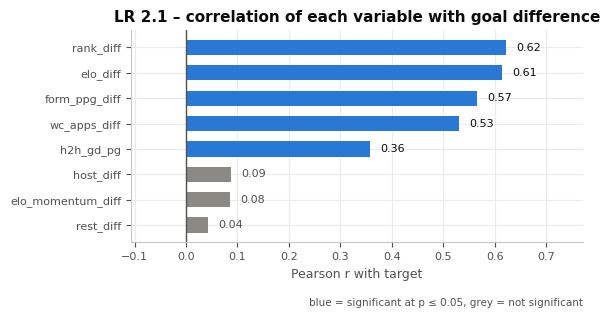

In [9]:
tc21 = target_correlations(d21, X21, Y21)
display(tc21)
plot_target_corr(tc21, "21_target_correlations", "LR 2.1 – correlation of each variable with goal difference")

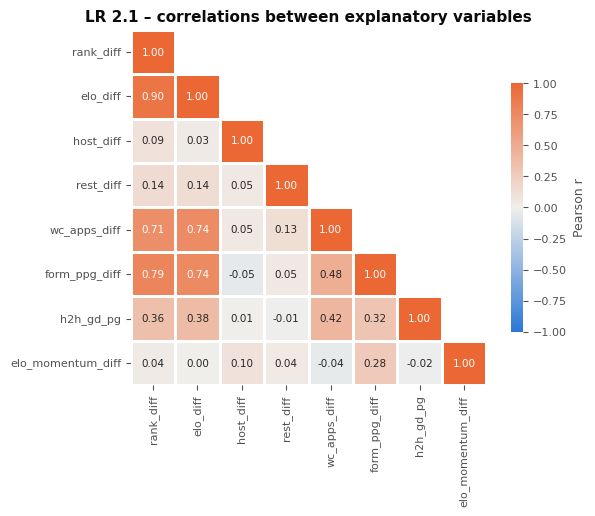

,VIF
rank_diff,7.277
elo_diff,6.158
form_ppg_diff,3.737
wc_apps_diff,2.535
elo_momentum_diff,1.274
h2h_gd_pg,1.252
host_diff,1.104
rest_diff,1.046


In [10]:
plot_corr_heatmap(d21, X21, "21_correlation_matrix", "LR 2.1 – correlations between explanatory variables")
display(vif(d21, X21).to_frame())

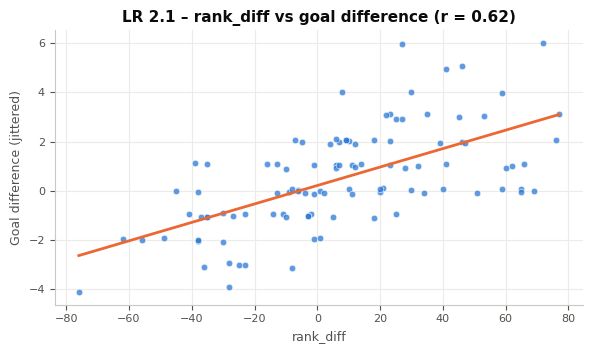

In [11]:
# Strongest predictor vs target, with least-squares line
best = tc21.index[0]
fig, ax = plt.subplots(figsize=(6, 3.6))
jit = np.random.default_rng(1).uniform(-.12, .12, len(d21))
ax.scatter(d21[best], d21[Y21] + jit, s=22, color=BLUE, alpha=.75, edgecolor="white", linewidth=.5)
b1, b0 = np.polyfit(d21[best], d21[Y21], 1)
xs = np.linspace(d21[best].min(), d21[best].max(), 50)
ax.plot(xs, b0 + b1 * xs, color=ORANGE, lw=2)
ax.set_xlabel(best); ax.set_ylabel("Goal difference (jittered)")
ax.set_title(f"LR 2.1 – {best} vs goal difference (r = {tc21.loc[best,'r']:.2f})")
fig.tight_layout(); save(fig, "21_top_predictor_scatter"); plt.show()

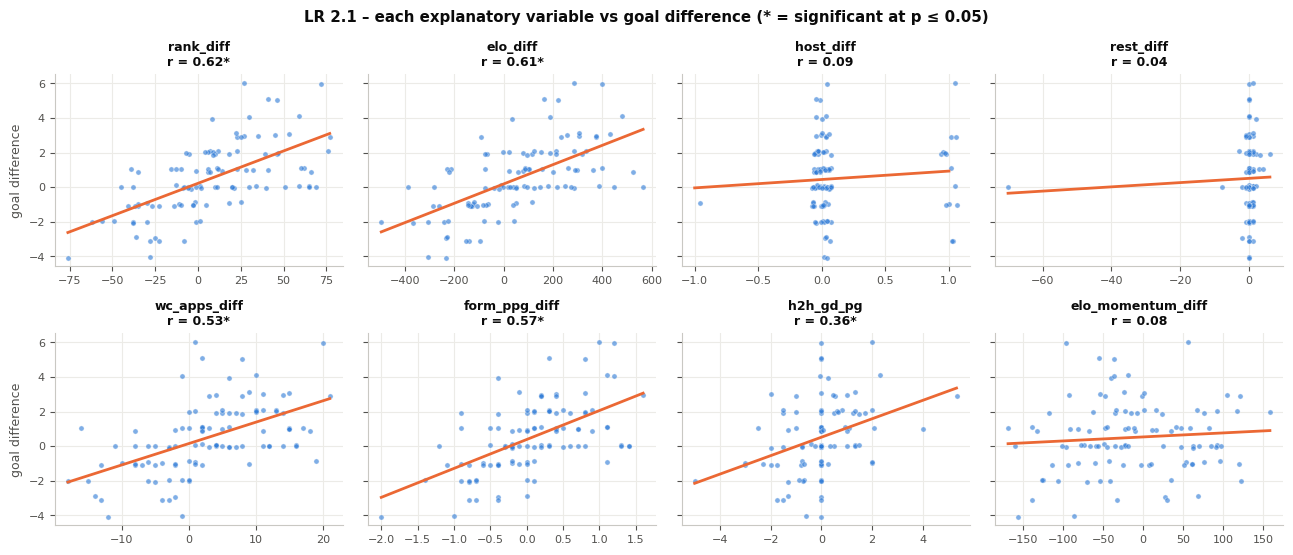

In [12]:
# Scatterplot of every explanatory variable against the target
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)
jit = np.random.default_rng(2).uniform(-.12, .12, len(d21))
for ax, c in zip(axes.flat, X21):
    xj = d21[c] + (np.random.default_rng(3).uniform(-.08, .08, len(d21)) if d21[c].nunique() <= 15 else 0)
    ax.scatter(xj, d21[Y21] + jit, s=14, color=BLUE, alpha=.6, edgecolor="white", linewidth=.4)
    b1, b0 = np.polyfit(d21[c], d21[Y21], 1)
    xs = np.linspace(d21[c].min(), d21[c].max(), 20)
    ax.plot(xs, b0 + b1 * xs, color=ORANGE, lw=2)
    r, p = tc21.loc[c, "r"], tc21.loc[c, "p_value"]
    ax.set_title(f"{c}\nr = {r:.2f}{'*' if p <= .05 else ''}", fontsize=9)
for ax in axes[:, 0]: ax.set_ylabel("goal difference")
fig.suptitle("LR 2.1 – each explanatory variable vs goal difference (* = significant at p ≤ 0.05)", fontweight="bold")
fig.tight_layout(); save(fig, "21_scatter_grid"); plt.show()

In [13]:
subset21 = eda_subset(tc21, d21, X21)
print("EDA-informed subset for 2.1:", subset21)

EDA-informed subset for 2.1: ['rank_diff', 'form_ppg_diff', 'wc_apps_diff', 'h2h_gd_pg']


### Model experiments & comparison

In [14]:
models21 = build_models(subset21)
scores21, oof21 = cross_validate(models21, d21[X21], d21[Y21])
summary21 = summarise(scores21)
summary21

,RMSE,RMSE_sd,MAE,R2,RMSE_gain_vs_baseline_%,t_vs_baseline,p_vs_baseline
model,,,,,,,
Linear regression (OLS),1.637,0.233,1.307,0.255,18.875,-13.946,1.102e-18
Baseline (predict mean),2.018,0.286,1.608,-0.116,-0.000,NaN,NaN


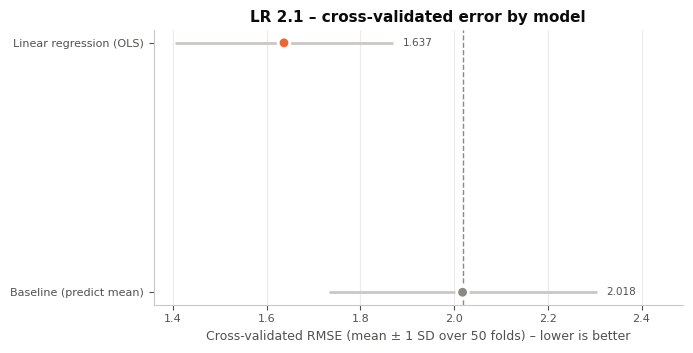

In [15]:
plot_comparison(summary21, "21_model_comparison", "LR 2.1 – cross-validated error by model")

6 matches above 4/n = 0.038


,team1,team2,stage,goal_diff,rest_diff,cooks_d
15,Saudi Arabia,Uruguay,Group,0,-70,7.979
27,Canada,Qatar,Group,6,1,0.135
57,Ecuador,Germany,Group,1,0,0.059
8,Germany,Curaçao,Group,6,0,0.053
13,Iran,New Zealand,Group,0,2,0.040
65,Senegal,Iraq,Group,5,0,0.039


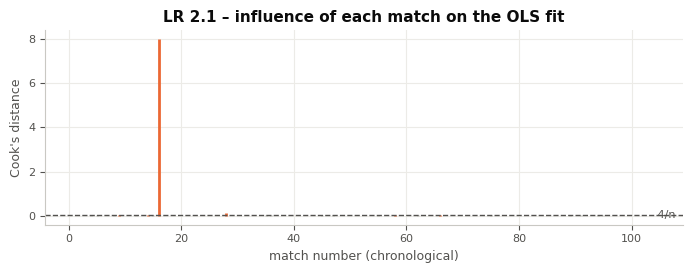

In [16]:
fit_tmp = sm.OLS(d21[Y21], sm.add_constant(d21[X21])).fit()
cooks = pd.Series(fit_tmp.get_influence().cooks_distance[0], index=d21.index)
thr = 4 / len(d21)
top = d21.assign(cooks_d=cooks).sort_values("cooks_d", ascending=False)
print(f"{(cooks > thr).sum()} matches above 4/n = {thr:.3f}")
display(top[["team1", "team2", "stage", "goal_diff", "rest_diff", "cooks_d"]].head(6).round(3))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.vlines(d21.match_no, 0, cooks, color=[ORANGE if c > thr else "#c9c8c3" for c in cooks], lw=2)
ax.axhline(thr, color=INK2, ls="--", lw=1); ax.text(104, thr, " 4/n", va="center", fontsize=8, color=INK2)
ax.set_xlabel("match number (chronological)"); ax.set_ylabel("Cook's distance")
ax.set_title("LR 2.1 – influence of each match on the OLS fit")
fig.tight_layout(); save(fig, "21_cooks_distance"); plt.show()

### 2.1 Interpretation of the full 8-variables

R² = 0.444, adjusted R² = 0.397, F p-value = 1.5e-09


,coef,CI_low,CI_high,p_value,std_beta
const,1.562e-01,-0.195,0.507,0.379,NaN
rank_diff,9.640e-03,-0.015,0.034,0.440,0.160
elo_diff,1.539e-03,-0.002,0.005,0.375,0.169
host_diff,3.834e-01,-0.511,1.278,0.397,0.068
rest_diff,-1.018e-02,-0.055,0.035,0.653,-0.035
wc_apps_diff,3.457e-02,-0.022,0.091,0.228,0.148
form_ppg_diff,6.114e-01,-0.259,1.481,0.166,0.206
h2h_gd_pg,1.612e-01,-0.092,0.415,0.210,0.108
elo_momentum_diff,6.610e-04,-0.004,0.005,0.781,0.024


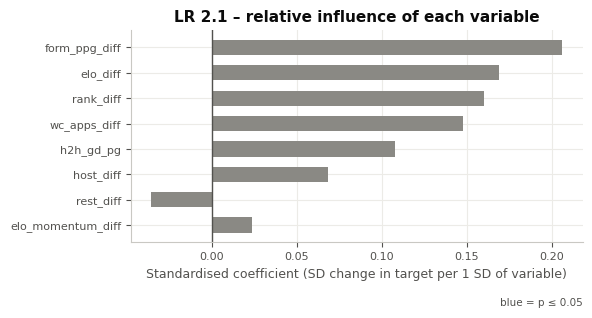

In [17]:
fit21, coefs21 = coef_table(d21, X21, Y21)
print(f"R² = {fit21.rsquared:.3f}, adjusted R² = {fit21.rsquared_adj:.3f}, F p-value = {fit21.f_pvalue:.2g}")
display(coefs21)
plot_std_betas(coefs21, "21_standardised_coefficients", "LR 2.1 – relative influence of each variable")

Best model by CV RMSE: Linear regression (OLS)


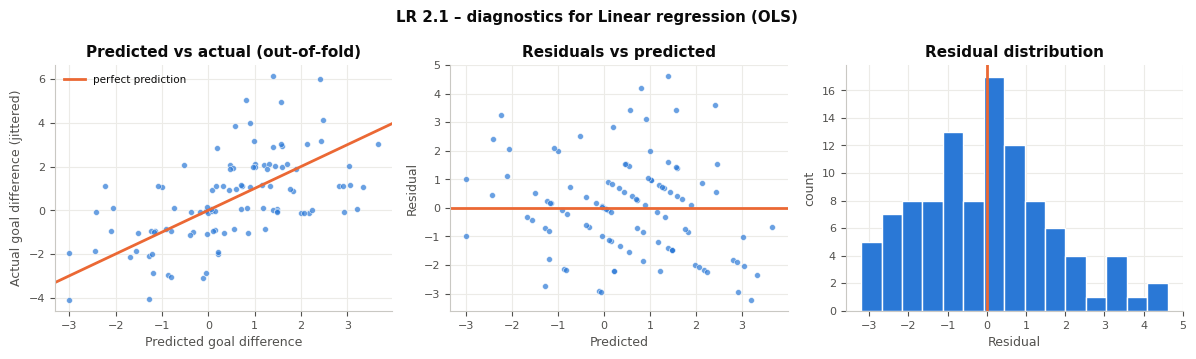

In [18]:
best21 = summary21.drop("Baseline (predict mean)").index[0]
print("Best model by CV RMSE:", best21)
plot_diagnostics(d21[Y21].values, oof21[best21], "21_diagnostics",
                 f"LR 2.1 – diagnostics for {best21}", "goal difference")

---
## 5. Competing algorithms: KNN, Decision Tree, Random Forest, Gradient Boosting


In [19]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

competitors = {
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                           random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                   subsample=0.8, random_state=SEED),
    "k-Nearest Neighbours": GridSearchCV(make_pipeline(IQRClipper(), StandardScaler(), KNeighborsRegressor()),
                                         {"kneighborsregressor__n_neighbors": [5, 10, 15, 20, 30],
                                          "kneighborsregressor__weights": ["uniform", "distance"]},
                                         cv=5, scoring="neg_root_mean_squared_error"),
    "Decision Tree": GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                                  {"max_depth": [2, 3, 4], "min_samples_leaf": [5, 10]},
                                  cv=5, scoring="neg_root_mean_squared_error"),
}
LINEAR = list(models21)
scores_comp, oof_comp = cross_validate(competitors, d21[X21], d21[Y21])
scores_all21 = pd.concat([scores21, scores_comp], ignore_index=True)
oof21.update(oof_comp)
summary_all21 = summarise(scores_all21)
summary_all21["family"] = ["baseline" if m.startswith("Baseline") else "linear" if m in LINEAR else "non-linear / ensemble"
                           for m in summary_all21.index]
summary_all21[["family", "RMSE", "RMSE_sd", "MAE", "R2", "RMSE_gain_vs_baseline_%", "p_vs_baseline"]].round(3)

,family,RMSE,RMSE_sd,MAE,R2,RMSE_gain_vs_baseline_%,p_vs_baseline
model,,,,,,,
k-Nearest Neighbours,non-linear / ensemble,1.608,0.243,1.290,0.287,20.317,0.0
Random Forest,non-linear / ensemble,1.610,0.252,1.286,0.280,20.242,0.0
Linear regression (OLS),linear,1.637,0.233,1.307,0.255,18.875,0.0
Decision Tree,non-linear / ensemble,1.698,0.289,1.360,0.200,15.857,0.0
Gradient Boosting,non-linear / ensemble,1.741,0.306,1.395,0.160,13.717,0.0
Baseline (predict mean),baseline,2.018,0.286,1.608,-0.116,-0.000,NaN


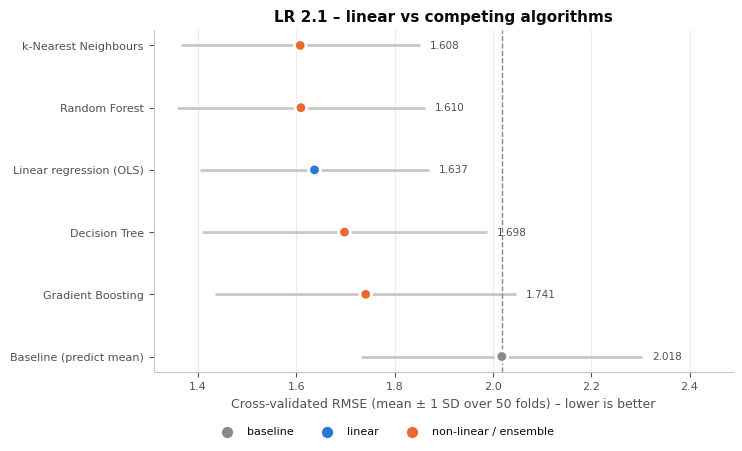

In [20]:
s = summary_all21.sort_values("RMSE", ascending=False)
fam_color = {"baseline": GREY, "linear": BLUE, "non-linear / ensemble": ORANGE}
fig, ax = plt.subplots(figsize=(7.5, 4.6))
y = np.arange(len(s))
ax.errorbar(s["RMSE"], y, xerr=s["RMSE_sd"], fmt="none", ecolor="#c9c8c3", elinewidth=2)
ax.scatter(s["RMSE"], y, s=70, color=[fam_color[f] for f in s.family], zorder=3, edgecolor="white", linewidth=2)
for yi, v, sd in zip(y, s["RMSE"], s["RMSE_sd"]):
    ax.text(v + sd + 0.02, yi, f"{v:.3f}", va="center", fontsize=7.5, color=INK2)
ax.axvline(s.loc["Baseline (predict mean)", "RMSE"], color=GREY, ls="--", lw=1)
ax.set_yticks(y, s.index); ax.grid(axis="y", visible=False)
ax.set_xlim(right=(s["RMSE"] + s["RMSE_sd"]).max() * 1.08)
ax.set_xlabel("Cross-validated RMSE (mean ± 1 SD over 50 folds) – lower is better")
ax.set_title("LR 2.1 – linear vs competing algorithms")
for lab, c in fam_color.items():
    ax.scatter([], [], color=c, s=50, label=lab)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.13), ncol=3)
fig.tight_layout(); save(fig, "21_competing_algorithms"); plt.show()

In [21]:
# Is the best non-linear model really different from the best linear model? Paired t-test on the 50 fold RMSEs.
fold_all = scores_all21.pivot_table(index=["repeat", "fold"], columns="model", values="RMSE")
best_lin = summary_all21[summary_all21.family == "linear"].index[0]
best_nl = summary_all21[summary_all21.family == "non-linear / ensemble"].index[0]
dd = fold_all[best_nl] - fold_all[best_lin]
t, p = stats.ttest_1samp(dd, 0)
print(f"Best linear: {best_lin} (RMSE {summary_all21.loc[best_lin,'RMSE']:.3f})")
print(f"Best non-linear/ensemble: {best_nl} (RMSE {summary_all21.loc[best_nl,'RMSE']:.3f})")
print(f"Mean difference (non-linear − linear) = {dd.mean():+.3f}, t(49) = {t:.2f}, p = {p:.3f}")

Best linear: Linear regression (OLS) (RMSE 1.637)
Best non-linear/ensemble: k-Nearest Neighbours (RMSE 1.608)
Mean difference (non-linear − linear) = -0.029, t(49) = -1.81, p = 0.076


---
## 6. Held-out test sets
Cross-validation was used. To estimate performance on genuinely unseen matches, we follow the lecturer's suggested training and validation

* **Test A – random 20% hold-out.**
* **Test B – train on the group stage, test on the knockouts.**

In [22]:
from sklearn.model_selection import train_test_split
candidates = {**models21, **competitors}

def holdout(train_idx, test_idx):
    out = {}
    for name, model in candidates.items():
        m = clone(model).fit(d21[X21].iloc[train_idx], d21[Y21].iloc[train_idx])
        pred = m.predict(d21[X21].iloc[test_idx])
        out[name] = np.sqrt(mean_squared_error(d21[Y21].iloc[test_idx], pred))
    return pd.Series(out)

idx = np.arange(len(d21))
tr_a, te_a = train_test_split(idx, test_size=0.2, random_state=SEED)
group = d21["stage"].str.startswith("Group").values
tr_b, te_b = idx[group], idx[~group]

hold = pd.DataFrame({
    f"Test A: random 20% (n={len(te_a)})": holdout(tr_a, te_a),
    f"Test B: knockouts (n={len(te_b)})": holdout(tr_b, te_b),
    "CV RMSE (for comparison)": summary_all21["RMSE"].reindex(list(candidates)),
}).sort_values(f"Test A: random 20% (n={len(te_a)})")
hold.round(3)

,Test A: random 20% (n=21),Test B: knockouts (n=32),CV RMSE (for comparison)
Random Forest,1.568,1.343,1.610
k-Nearest Neighbours,1.576,1.310,1.608
Linear regression (OLS),1.716,1.416,1.637
Decision Tree,1.750,1.632,1.698
Gradient Boosting,1.916,1.619,1.741
Baseline (predict mean),2.108,1.627,2.018


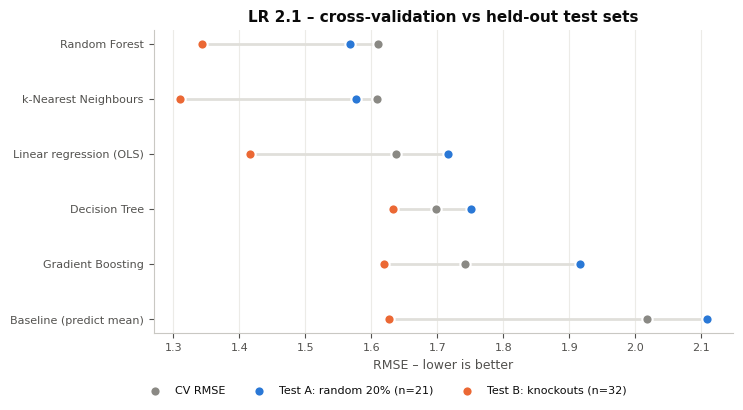

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
h = hold.sort_values(hold.columns[0], ascending=False)
y = np.arange(len(h))
ax.scatter(h.iloc[:, 2], y, s=55, color=GREY, label="CV RMSE", zorder=3, edgecolor="white", linewidth=1.5)
ax.scatter(h.iloc[:, 0], y, s=55, color=BLUE, label=h.columns[0], zorder=3, edgecolor="white", linewidth=1.5)
ax.scatter(h.iloc[:, 1], y, s=55, color=ORANGE, label=h.columns[1], zorder=3, edgecolor="white", linewidth=1.5)
for yi, row in zip(y, h.itertuples(index=False)):
    ax.plot([min(row), max(row)], [yi, yi], color="#e0dfda", lw=2, zorder=1)
ax.set_yticks(y, h.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE – lower is better"); ax.set_title("LR 2.1 – cross-validation vs held-out test sets")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.14), ncol=3)
fig.tight_layout(); save(fig, "21_holdout_tests"); plt.show()

---
## 7. Choosing the final model

In [24]:
best = "Linear regression (OLS)"
fold = scores21.pivot_table(index=["repeat", "fold"], columns="model", values="RMSE")
diff = fold[best] - fold["Baseline (predict mean)"]
t, p = stats.ttest_1samp(diff, 0)
print(f"Linear regression RMSE {summary21.loc[best, 'RMSE']:.3f} vs baseline {summary21.loc['Baseline (predict mean)', 'RMSE']:.3f}")
print(f"Paired t-test: mean difference = {diff.mean():.3f}, t({len(diff)-1}) = {t:.2f}, p = {p:.4f}")

Linear regression RMSE 1.637 vs baseline 2.018
Paired t-test: mean difference = -0.381, t(49) = -13.95, p = 0.0000


Final model: Linear regression (OLS)  ->  variables ['rank_diff', 'elo_diff', 'host_diff', 'rest_diff', 'wc_apps_diff', 'form_ppg_diff', 'h2h_gd_pg', 'elo_momentum_diff']
R² = 0.447, adjusted R² = 0.401, F p-value = 1.1e-09


,coef,CI_low,CI_high,p_value
const,1.592e-01,-0.189,0.507,0.366
rank_diff,8.400e-03,-0.016,0.033,0.496
elo_diff,1.600e-03,-0.002,0.005,0.354
host_diff,3.673e-01,-0.525,1.260,0.416
rest_diff,9.060e-02,-0.108,0.289,0.367
wc_apps_diff,3.170e-02,-0.025,0.088,0.269
form_ppg_diff,6.571e-01,-0.205,1.519,0.134
h2h_gd_pg,1.713e-01,-0.081,0.424,0.181
elo_momentum_diff,3.000e-04,-0.004,0.005,0.910


+100 Elo points for team A changes the predicted margin by +0.16 goals (95% CI -0.18 to +0.50).
+10 FIFA ranking places for team A changes the predicted margin by +0.08 goals (95% CI -0.16 to +0.33).
+0.5 points per game of form for team A changes the predicted margin by +0.33 goals (95% CI -0.10 to +0.76).


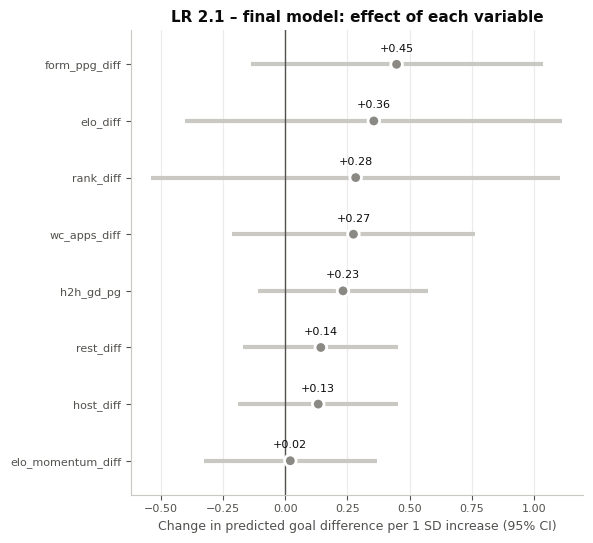

In [25]:
# Refit the best model from cross-validation on all 104 matches, with statsmodels for confidence intervals
final_cols = X21
d21_fit = cap_rest(d21)
final_fit = sm.OLS(d21_fit[Y21], sm.add_constant(d21_fit[final_cols])).fit()
print(f"Final model: {best}  ->  variables {final_cols}")
print(f"R² = {final_fit.rsquared:.3f}, adjusted R² = {final_fit.rsquared_adj:.3f}, F p-value = {final_fit.f_pvalue:.2g}")
ci = final_fit.conf_int()
coef = pd.DataFrame({"coef": final_fit.params, "CI_low": ci[0], "CI_high": ci[1], "p_value": final_fit.pvalues})
display(coef.round(4))
for var, step, label in [("elo_diff", 100, "100 Elo points"), ("rank_diff", 10, "10 FIFA ranking places"),
                         ("form_ppg_diff", 0.5, "0.5 points per game of form")]:
    if var in final_cols:
        b = final_fit.params[var]
        print(f"+{label} for team A changes the predicted margin by {step*b:+.2f} goals "
              f"(95% CI {step*ci.loc[var, 0]:+.2f} to {step*ci.loc[var, 1]:+.2f}).")

# coefficient
sd = d21_fit[final_cols].std()
eff = pd.DataFrame({"est": final_fit.params[final_cols] * sd, "lo": ci.loc[final_cols, 0] * sd,
                    "hi": ci.loc[final_cols, 1] * sd}).sort_values("est")
fig, ax = plt.subplots(figsize=(6, 0.7 + 0.6 * len(eff)))
y = np.arange(len(eff))
ax.hlines(y, eff.lo, eff.hi, color="#c9c8c3", lw=3)
ax.scatter(eff.est, y, s=70, color=[BLUE if (l > 0 or h < 0) else GREY for l, h in zip(eff.lo, eff.hi)],
           zorder=3, edgecolor="white", linewidth=2)
for yi, v in zip(y, eff.est): ax.text(v, yi + 0.22, f"{v:+.2f}", ha="center", fontsize=8, color=INK)
ax.axvline(0, color=INK2, lw=1); ax.set_yticks(y, eff.index); ax.grid(axis="y", visible=False)
ax.set_ylim(-0.6, len(eff) - 0.4)
ax.set_xlabel("Change in predicted goal difference per 1 SD increase (95% CI)")
ax.set_title("LR 2.1 – final model: effect of each variable")
fig.tight_layout(); save(fig, "21_final_model_effects"); plt.show()

class _Final:
    def predict(self, X): return final_fit.predict(sm.add_constant(cap_rest(X)[final_cols], has_constant="add"))
final21 = _Final()

## Prediction

In [26]:

ex = d21[["team1", "team2", "goal_diff"]].copy()
ex["predicted"] = final21.predict(d21[X21]).round(2)
ex["predicted_winner"] = np.where(ex.predicted > 0.5, ex.team1, np.where(ex.predicted < -0.5, ex.team2, "draw-ish"))
display(ex.iloc[[0, 15, 60, 103]])

oof = oof21[best]
nd = d21[Y21] != 0
print(f"Out-of-fold: predicted winner correct in {(np.sign(oof[nd]) == np.sign(d21[Y21][nd])).mean():.1%} "
      f"of the {nd.sum()} decisive matches")

,team1,team2,goal_diff,predicted,predicted_winner
0,Mexico,South Africa,2,2.55,Mexico
15,Saudi Arabia,Uruguay,0,-1.86,Uruguay
60,Egypt,Iran,0,0.01,draw-ish
103,Spain,Argentina,1,0.16,draw-ish


Out-of-fold: predicted winner correct in 85.0% of the 80 decisive matches
